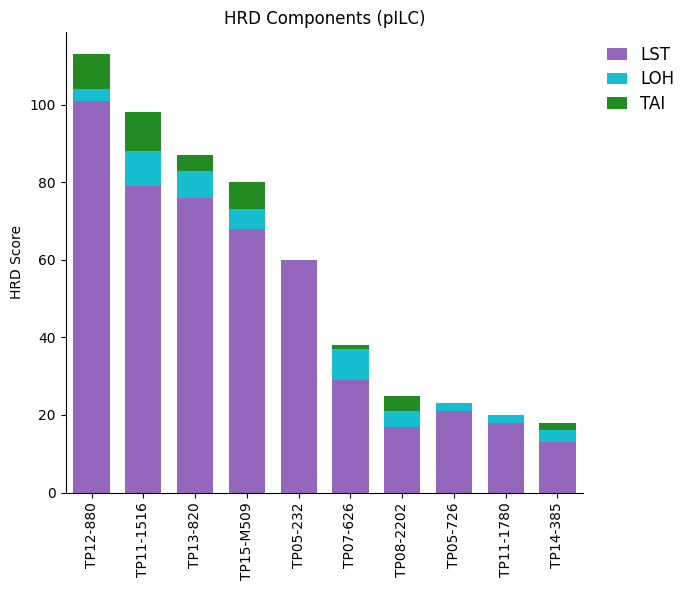

Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/Grant/OGM/HRD_pILC_only.png


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from matplotlib.patches import Patch

# =========================
# Load data
# =========================
infile = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/Grant/OGM/Tumor_HRD.csv"
df = pd.read_csv(infile)

# Clean spaces if present
df["Histology"] = df["Histology"].astype(str).str.strip()
df["Sample"] = df["Sample"].astype(str).str.strip()
df["Source"] = df["Source"].astype(str).str.strip()

# Ensure numeric columns
for col in ["LST", "LOH", "TAI", "Total"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Optional: re-calculate total if needed
df["Total_check"] = df["LST"] + df["LOH"] + df["TAI"]

# If you want to overwrite Total with recalculated value, uncomment:
# df["Total"] = df["Total_check"]

# =========================
# Colors
# =========================

# HRD component colors
color_lst = "#9467bd"   # purple
color_loh = "#17becf"   # cyan
color_tai = "#228B22"   # green

# Histology colors
histology_colors = {
    "ILC": "#FF0000",     # red
    "pILC": "#FFA500",    # orange
    "NST": "#0000FF"      # blue
}

# Output directory
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/Grant/OGM"
os.makedirs(OUTDIR, exist_ok=True)

# =========================
# Plot function
# =========================
def plot_hrd(df_plot, title, outfile, annotate_histology=False):

    df_plot = df_plot.sort_values("Total", ascending=False).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(7, 6))

    x = range(len(df_plot))
    bar_w = 0.7

    # ---- Stacked bars
    ax.bar(x, df_plot["LST"], width=bar_w, color=color_lst, label="LST")
    ax.bar(x, df_plot["LOH"], width=bar_w, bottom=df_plot["LST"], color=color_loh, label="LOH")
    ax.bar(
        x,
        df_plot["TAI"],
        width=bar_w,
        bottom=df_plot["LST"] + df_plot["LOH"],
        color=color_tai,
        label="TAI"
    )

    # ---- Axis settings
    ax.set_xlim(-0.5, len(df_plot) - 0.5)
    ax.set_xticks(list(x))
    ax.set_xticklabels(df_plot["Sample"], rotation=90)
    ax.set_ylabel("HRD Score")
    ax.set_title(title)

    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

    # =========================
    # Histology annotation strip
    # =========================
    if annotate_histology:
        bar_h = 0.03
        y0 = -0.25

        for i, row in df_plot.iterrows():
            ax.add_patch(plt.Rectangle(
                (i - bar_w/2, y0),
                bar_w,
                bar_h,
                transform=ax.get_xaxis_transform(),
                color=histology_colors.get(row["Histology"], "grey"),
                clip_on=False
            ))

        # Build histology legend dynamically based on histologies present in current plot
        present_histologies = [h for h in ["NST", "ILC", "pILC"] if h in df_plot["Histology"].unique()]
        hist_legend = [Patch(color=histology_colors[h], label=h) for h in present_histologies]

        ax.legend(
            handles=[
                Patch(color=color_lst, label="LST"),
                Patch(color=color_loh, label="LOH"),
                Patch(color=color_tai, label="TAI")
            ] + hist_legend,
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            fontsize=12,
            title_fontsize=13,
            frameon=False,
            labelspacing=0.4,
            handlelength=1.2,
            borderpad=0.3
        )

    else:
        ax.legend(
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            fontsize=12,
            title_fontsize=13,
            frameon=False,
            labelspacing=0.4,
            handlelength=1.2,
            borderpad=0.3
        )

    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", outfile)

# =========================
# 1) pILC only
# =========================
df_pilc = df[df["Histology"] == "pILC"]

plot_hrd(
    df_pilc,
    "HRD Components (pILC)",
    os.path.join(OUTDIR, "HRD_pILC_only.png"),
    annotate_histology=False
)